# Задача 4.14
# Объединение корзин и формула Байеса

## Условие
В первой корзине 6 шаров, число белых $K_1\sim\mathrm{Bin}(3,0.8)$. Во второй 11 шаров, число белых $K_2\sim\mathrm{Bin}(4,0.7)$. Все 17 шаров объединяют. A — выбран белый шар, H — выбран шар из первой корзины. Найти $P(A)$ и $P(H\mid A)$.

## Теория с нуля и решение вручную
### 1. Параметры распределения и размер корзины
$\mathrm{Bin}(3,0.8)$ означает, что число белых может быть от 0 до 3, хотя всего в первой корзине 6 шаров. Не нужно подменять параметр 3 числом 6. Аналогично во второй максимум 4 белых при 11 шарах. Ожидания:
$$E[K_1]=3\cdot0.8=2.4,\qquad E[K_2]=4\cdot0.7=2.8.$$
Ожидание может быть нецелым: это среднее при многих повторениях, а не состав одной конкретной корзины.

### 2. Вероятность белого шара
При заданных $K_1,K_2$ шанс белого равен $(K_1+K_2)/17$. Усредняем:
$$P(A)=\frac{E[K_1]+E[K_2]}{17}=\frac{5.2}{17}=\frac{26}{85}\approx0.30588235.$$
То же по полной вероятности: $P(H)=6/17$, $P(A\mid H)=2.4/6=0.4$; $P(\overline H)=11/17$, $P(A\mid\overline H)=2.8/11$. После перемножения и сложения получаем тот же ответ.

### 3. Байес и смена условия
Совместная вероятность извлечь белый именно из первой корзины:
$$P(H\cap A)=P(H)P(A\mid H)=\frac{2.4}{17}=\frac{12}{85}.$$
Формула Байеса:
$$P(H\mid A)=\frac{P(H)P(A\mid H)}{P(A)}=\frac{2.4}{5.2}=\frac6{13}\approx0.46153846.$$
$P(H\mid A)$ и $P(A\mid H)$ — разные вероятности: первая выбирает происхождение среди белых, вторая — цвет среди шаров первой корзины. Не следует усреднять случайные дроби $K_1/(K_1+K_2)$ без учёта вероятности вообще извлечь белый: это другой эксперимент.

### 4. Переход к коду
Для моделирования принимаем независимость начальных составов корзин. Для двух полученных формул она не обязательна: достаточно указанных ожиданий и равномерного выбора одного из 17 шаров. Номера 0…5 относятся к первой корзине, 6…16 — ко второй. В каждом блоке первые $K_i$ номеров белые. Для условной оценки делим число белых из первой на **все извлечённые белые**, а не на $N$.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

A: выбран белый: успехов 45989, знаменатель 150000
  частота = 0.30659333; ориентир 95%: [0.30425995; 0.30892672]
  теория = 0.30588235; разность = +0.00071098


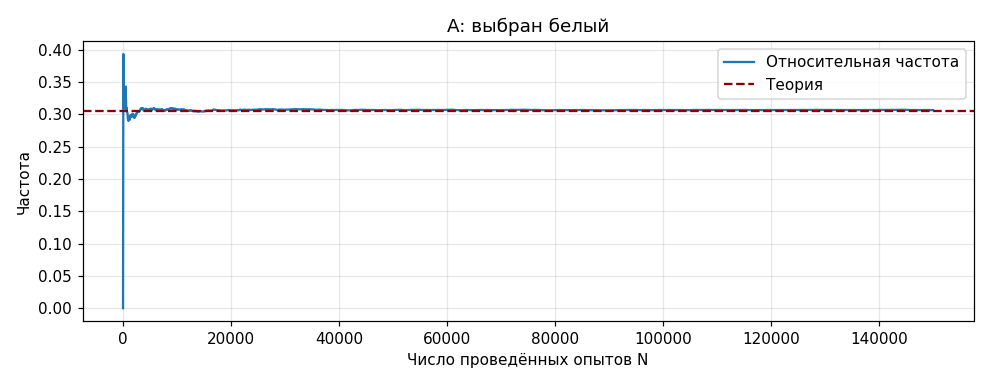

H при условии A: белый из первой корзины: успехов 21217, знаменатель 45989
  частота = 0.46134945; ориентир 95%: [0.45679331; 0.46590560]
  теория = 0.46153846; разность = -0.00018901


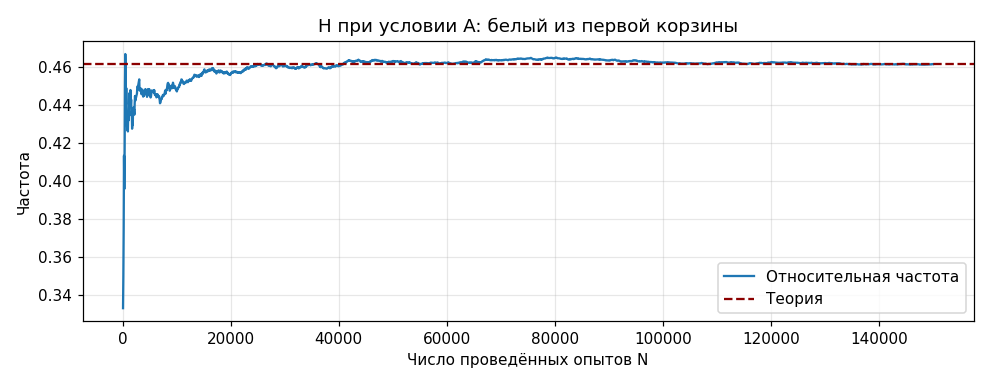

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 150_000
K1 = rng.binomial(3, 0.8, size=N)
K2 = rng.binomial(4, 0.7, size=N)
selected = rng.integers(0, 17, size=N)
H = selected < 6
A = (H & (selected < K1)) | (~H & (selected-6 < K2))
report(A, 'A: выбран белый', Fraction(26,85))
report(H, 'H при условии A: белый из первой корзины', Fraction(6,13), A)
